# Valor añadido por sectores de actividad

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"               # carpeta en research/temas/
GRAFICA_ID = "valor-anadido-sectores"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Valor añadido por sectores de actividad"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "composicion"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias | composicion
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del valor añadido bruto total, a precios corrientes"
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El peso de cada uno de los **diez grandes sectores de actividad** (la agregación A10 de las cuentas nacionales) en el valor añadido bruto de la economía, a precios corrientes: cuánto de lo que produce cada país sale de la agricultura, la industria, la construcción, el comercio, el transporte y la hostelería, las finanzas, las actividades inmobiliarias, etc. La gráfica muestra el último año con dato de todos los sectores en cada serie de la cesta; el JSON y el CSV traen toda la serie.

**Para qué sirve.** Muestra la estructura productiva: los sectores tienen productividades muy distintas, así que el peso de cada uno ayuda a entender las diferencias de productividad media entre países (ver `empleo-empresas-baja-productividad` y `empleo-sectores-alta-tecnologia`).

**Solo en el notebook** (`en_web: false`): la web aún no dibuja esta vista.

**Limitaciones.**
- Los diez sectores son muy amplios: dentro de cada uno hay actividades de productividad muy distinta (la industria incluye desde la alimentación hasta la farmacia).
- El valor añadido de las actividades inmobiliarias incluye el alquiler imputado de las viviendas en propiedad, que no es una actividad de empresas.
- La OCDE no publica el agregado de la OCDE por sectores.

## 2. Descarga

**OCDE, cuentas nacionales anuales: PIB por el lado de la oferta** (`OECD.SDD.NAD,DSD_NAMAIN10@DF_TABLE1_OUTPUT`, versión 2.0): valor añadido bruto (`B1G`) del total de la economía (`_T`) y de cada sector de la A10 (`A`, `BTE`, `F`, `GTI`, `J`, `K`, `L`, `M_N`, `OTQ`, `RTU`) y de la industria manufacturera (`C`, para las notas), a precios corrientes (`V`) en moneda nacional (`XDC`), de España, la UE-27 (`EU27_2020`), EE. UU. y Canadá.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

from datetime import date

import pandas as pd
import requests

from lib import estilos, oecd
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

HOY = date.today().isoformat()
DATAFLOW = "OECD.SDD.NAD,DSD_NAMAIN10@DF_TABLE1_OUTPUT,2.0"
# Dimensiones: frecuencia . país . sector . contrapartida . operación . activo . actividad . gasto . unidad . precios . transformación . tabla
CLAVE = "A.{AREA}.S1.S1.B1G._Z.{ACT}._Z.XDC.V.N.T0101"
AREAS = {"ESP": "espana", "EU27_2020": "ue27", "USA": "eeuu", "CAN": "canada"}
# Los diez sectores de la A10, en el orden de la NACE / CIIU
SECTORES = {
    "A": ("agricultura", "Agricultura, ganadería y pesca"),
    "BTE": ("industria", "Industria y energía"),
    "F": ("construccion", "Construcción"),
    "GTI": ("comercio-transporte-hosteleria", "Comercio, transporte y hostelería"),
    "J": ("informacion-comunicaciones", "Información y comunicaciones"),
    "K": ("finanzas-seguros", "Finanzas y seguros"),
    "L": ("inmobiliarias", "Actividades inmobiliarias"),
    "M_N": ("profesionales-administrativas", "Actividades profesionales, científicas y administrativas"),
    "OTQ": ("administracion-educacion-sanidad", "Administración pública, educación y sanidad"),
    "RTU": ("otros-servicios", "Actividades artísticas y otros servicios"),
}
sesion = requests.Session()
va = {}
for act in [*SECTORES, "_T", "C"]:
    df, fuentes_act = oecd.get(DATAFLOW, CLAVE.replace("{ACT}", act), areas=AREAS, desde=DESDE, sesion=sesion)
    va[act] = df.set_index(["serie", "periodo"])["valor"]
print({a: v.index.get_level_values(0).unique().tolist() for a, v in va.items()})

# ¿Publica la OCDE el agregado de la OCDE por sectores?
try:
    oecd.get(DATAFLOW, CLAVE.replace("{ACT}", "C"), areas={"OECD": "ocde"}, desde=DESDE, sesion=sesion)
    OCDE_POR_SECTORES = True
except oecd.OecdError as e:
    assert "NoRecordsFound" in str(e) or "NoResultsFound" in str(e), f"OECD: error distinto de «sin datos»: {e}"
    OCDE_POR_SECTORES = False
print("Agregado OCDE por sectores:", OCDE_POR_SECTORES)

{'A': ['canada', 'eeuu', 'espana', 'ue27'], 'BTE': ['canada', 'eeuu', 'espana', 'ue27'], 'F': ['canada', 'eeuu', 'espana', 'ue27'], 'GTI': ['canada', 'eeuu', 'espana', 'ue27'], 'J': ['canada', 'eeuu', 'espana', 'ue27'], 'K': ['canada', 'eeuu', 'espana', 'ue27'], 'L': ['canada', 'eeuu', 'espana', 'ue27'], 'M_N': ['canada', 'eeuu', 'espana', 'ue27'], 'OTQ': ['canada', 'eeuu', 'espana', 'ue27'], 'RTU': ['canada', 'eeuu', 'espana', 'ue27'], '_T': ['canada', 'eeuu', 'espana', 'ue27'], 'C': ['canada', 'eeuu', 'espana', 'ue27']}


Agregado OCDE por sectores: False


## 3. Transformación

1. **Peso de cada sector** = valor añadido del sector / valor añadido total × 100, del mismo país y año (a precios corrientes y en moneda nacional, así que no hace falta convertir monedas).
2. Se comprueba que los diez sectores suman el total (salvo redondeos de la fuente).
3. La serie `ocde` queda sin datos: la OCDE no publica su agregado por sectores (se comprueba en la descarga).

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


assert not OCDE_POR_SECTORES, "La OCDE ya publica su agregado por sectores: añádelo a la serie ocde"
total = va["_T"]
filas = []
for act, (clave, _) in SECTORES.items():
    peso = (va[act] / total.reindex(va[act].index) * 100).dropna()
    filas.append(peso.reset_index().assign(serie=lambda d, c=clave: d["serie"] + "__" + c))
df = pd.concat(filas, ignore_index=True)[["serie", "periodo", "valor"]]
suma = df.assign(pais=df["serie"].str.split("__").str[0]).groupby(["pais", "periodo"])["valor"].agg(["sum", "count"])
completos = suma[suma["count"] == len(SECTORES)]
assert completos["sum"].between(99, 101).all(), completos[~completos["sum"].between(99, 101)]
composicion = {c: n for c, n in SECTORES.values()}
vacias = pd.DataFrame({"serie": [f"ocde__{c}" for c in composicion], "periodo": DESDE, "valor": float("nan")})
df = pd.concat([df, vacias], ignore_index=True)

_, FLUJO, VERSION = DATAFLOW.split(",")
fuentes = [
    *[FuenteMeta(f"{s}__{c}", oecd.ORGANISMO, f"{FLUJO} (versión {VERSION}): B1G, A10, V, XDC", oecd.URL_EXPLORER, HOY)
      for s in AREAS.values() for c in composicion],
    *[FuenteMeta(f"ocde__{c}", oecd.ORGANISMO, f"{FLUJO} (consultada: sin agregado OECD por sectores)", oecd.URL_EXPLORER, HOY)
      for c in composicion],
]


def ultimo_completo(serie):
    anios = completos.xs(serie).index
    return int(anios.max())


a_es, a_ue = ultimo_completo("espana"), ultimo_completo("ue27")
manufactura = lambda s, a: va["C"].get((s, a)) / total.get((s, a)) * 100  # noqa: E731
NOTAS = [
    f"OCDE, cuentas nacionales anuales, PIB por el lado de la oferta ({FLUJO}, versión {VERSION}): valor añadido bruto "
    "de cada sector de la agregación A10 de la CIIU/NACE en % del valor añadido bruto total, a precios corrientes y en "
    "moneda nacional. La UE-27 (EU27_2020), en euros, la publica la OCDE a partir de Eurostat.",
    f"La industria manufacturera, que es parte de «Industria y energía», pesa el {es(manufactura('espana', a_es))} % "
    f"del valor añadido en España ({a_es}) y el {es(manufactura('ue27', a_ue))} % en la UE-27 ({a_ue}).",
    "Las actividades inmobiliarias incluyen el alquiler imputado de las viviendas ocupadas por sus propietarios.",
    "OCDE: sin dato; la OCDE no publica el agregado de sus miembros por sectores y no se calcula una media propia "
    "(METODOLOGIA §2.3).",
    "Gráfica solo en el notebook: cada barra es el último año con dato de todos los sectores de esa serie.",
]

## 4. Visualización

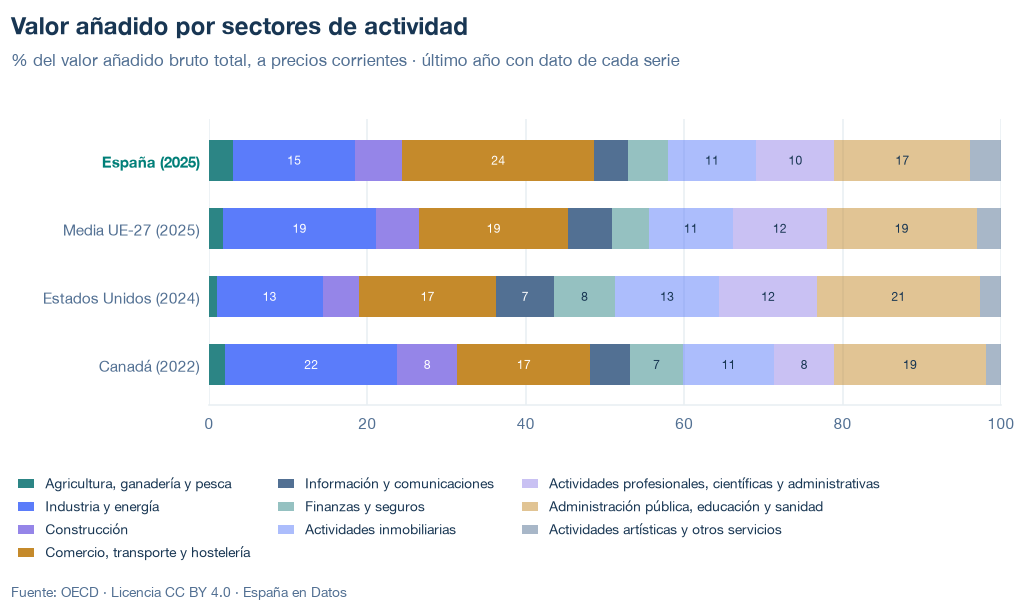

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    composicion=composicion,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    composicion=composicion, path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/valor-anadido-sectores.json y data/valor-anadido-sectores.csv


## 6. Fuentes, notas y licencia

- OCDE, cuentas nacionales anuales: `OECD.SDD.NAD,DSD_NAMAIN10@DF_TABLE1_OUTPUT,2.0` (`B1G`, actividades A10 y `C`, `V`, `XDC`).

La fecha de consulta de cada serie está en `fuentes` del JSON; `writer.py` añade a las notas el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.